# Task 53. Exercise on Decision Tree

In [1]:
# ===== Decision Tree Classification with Scikit-learn =====
# Importing required libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [2]:
# ===== Loading Data =====
# Pima Indians Diabetes dataset (no header row, so we give the column names)
columns = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
pima = pd.read_csv('datasets/diabetes.csv', header=None, names=columns)

In [3]:
pima.head()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
pima.shape

(768, 9)

In [5]:
# ===== Feature Selection =====
# split the columns into features (X) and the target variable (y)
features = ['pregnant', 'insulin', 'bmi', 'age', 'glucose', 'bp', 'pedigree']
X = pima[features]
y = pima['label']

In [6]:
# ===== Splitting Data =====
# 70% training and 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 537
Test rows: 231


In [7]:
# ===== Building the Decision Tree Model =====
tree_model = DecisionTreeClassifier()
tree_model.fit(X_train, y_train)

y_pred = tree_model.predict(X_test)

In [8]:
# ===== Evaluating the Model =====
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.7056277056277056


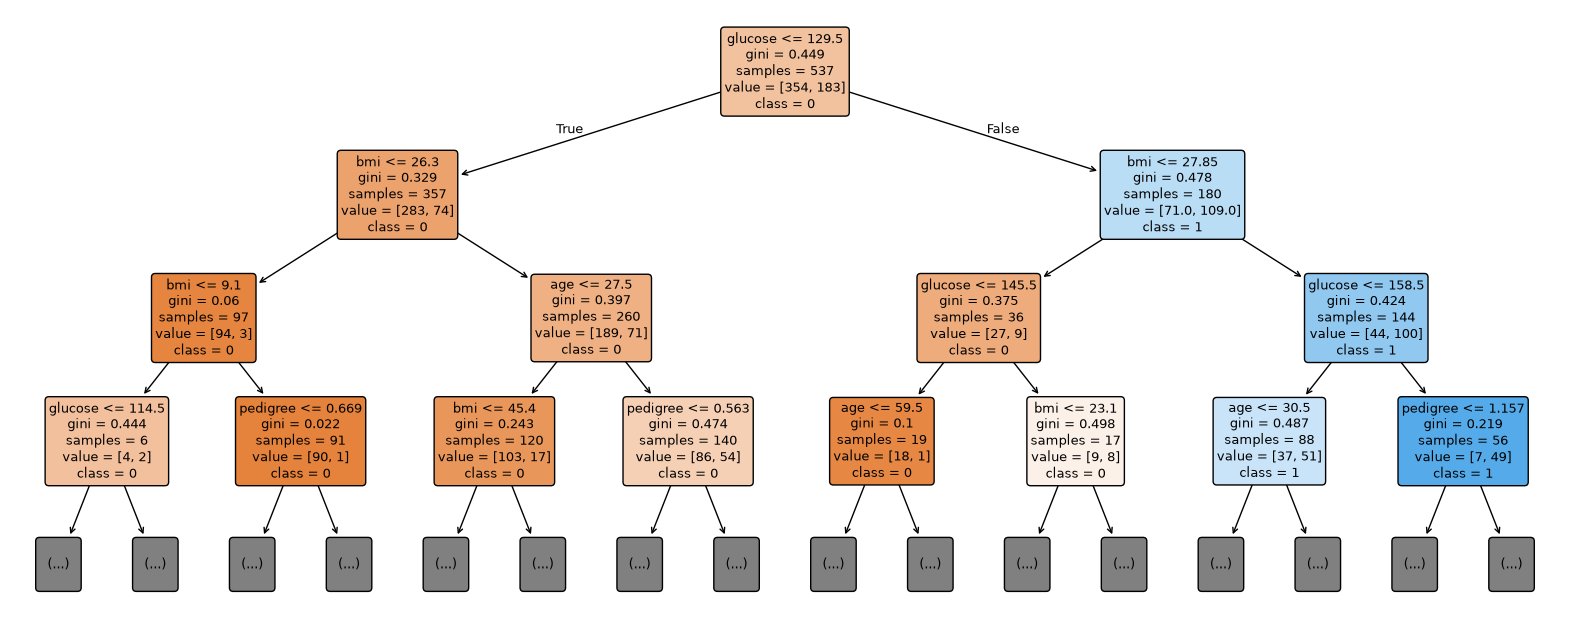

In [9]:
# ===== Visualizing the Decision Tree =====
# The full tree is very deep, so only the top 3 levels are drawn
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(tree_model, feature_names=features, class_names=['0', '1'],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.show()

In [10]:
# ===== Optimizing Decision Tree Performance =====
# use entropy as the split criterion and limit the depth of the tree
tree_model = DecisionTreeClassifier(criterion="entropy", max_depth=3)
tree_model.fit(X_train, y_train)

y_pred = tree_model.predict(X_test)
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.7705627705627706


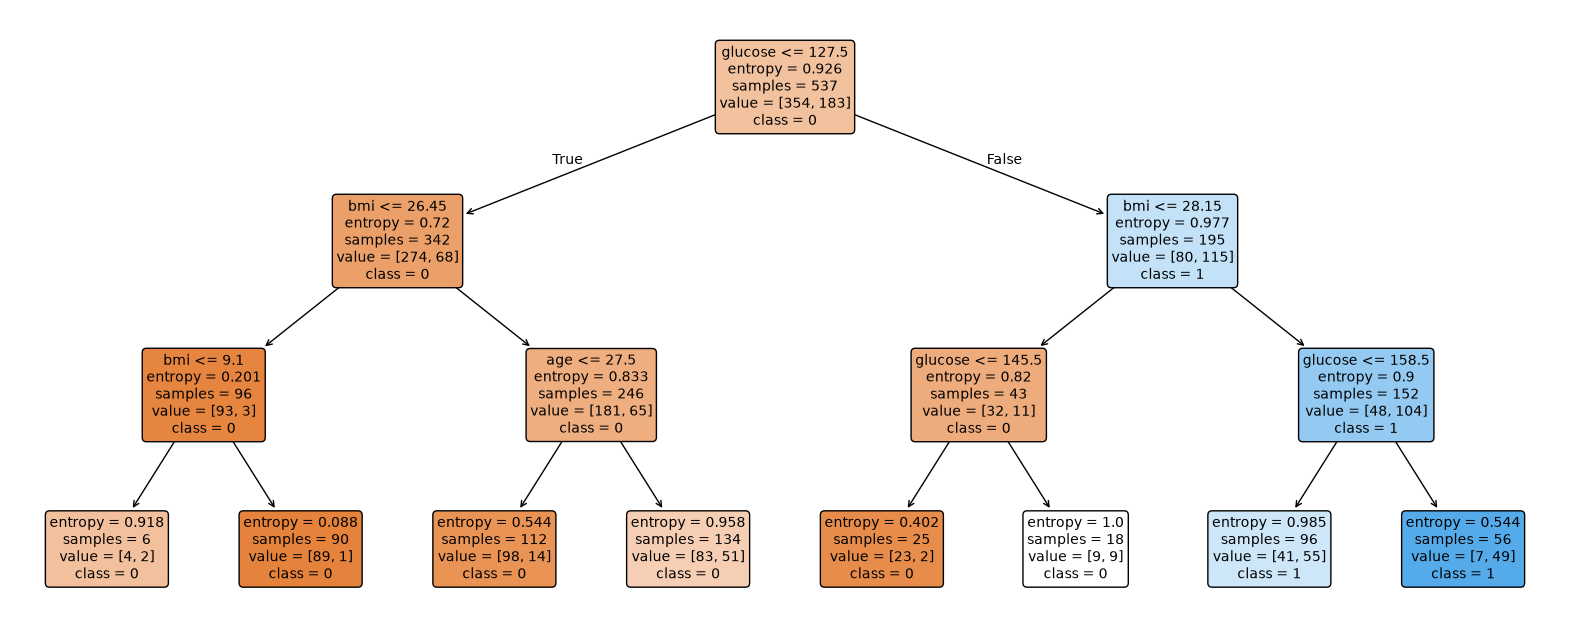

In [11]:
# Visualizing the pruned tree
plt.figure(figsize=(20, 8))
plot_tree(tree_model, feature_names=features, class_names=['0', '1'],
          filled=True, rounded=True, fontsize=10)
plt.show()

In [12]:
# Text version of the same tree
from sklearn.tree import export_text
print(export_text(tree_model, feature_names=features))

|--- glucose <= 127.50
|   |--- bmi <= 26.45
|   |   |--- bmi <= 9.10
|   |   |   |--- class: 0
|   |   |--- bmi >  9.10
|   |   |   |--- class: 0
|   |--- bmi >  26.45
|   |   |--- age <= 27.50
|   |   |   |--- class: 0
|   |   |--- age >  27.50
|   |   |   |--- class: 0
|--- glucose >  127.50
|   |--- bmi <= 28.15
|   |   |--- glucose <= 145.50
|   |   |   |--- class: 0
|   |   |--- glucose >  145.50
|   |   |   |--- class: 0
|   |--- bmi >  28.15
|   |   |--- glucose <= 158.50
|   |   |   |--- class: 1
|   |   |--- glucose >  158.50
|   |   |   |--- class: 1



In [13]:
# ===== Decision Tree vs. Decision Stump =====
# a decision stump is a tree with only one split
stump = DecisionTreeClassifier(max_depth=1)
stump.fit(X_train, y_train)

print("Stump accuracy:", metrics.accuracy_score(y_test, stump.predict(X_test)))

Stump accuracy: 0.7532467532467533
